In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("tips.csv")
shape = df.shape
print(f"Tips.csv file has {shape[0]} rows, and {shape[1]} columns")
print()
print(df.head())


Tips.csv file has 244 rows, and 7 columns

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    str    
 3   smoker      244 non-null    str    
 4   day         244 non-null    str    
 5   time        244 non-null    str    
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), str(4)
memory usage: 13.5 KB


In [10]:
df.describe().round(1)

,total_bill,tip,size
count,244.0,244.0,244.0
mean,19.8,3.0,2.6
std,8.9,1.4,1.0
min,3.1,1.0,1.0
25%,13.3,2.0,2.0
50%,17.8,2.9,2.0
75%,24.1,3.6,3.0
max,50.8,10.0,6.0


In [9]:
df.isna().sum()

total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64

In [11]:
print(df["sex"].value_counts())

sex
Male      157
Female     87
Name: count, dtype: int64


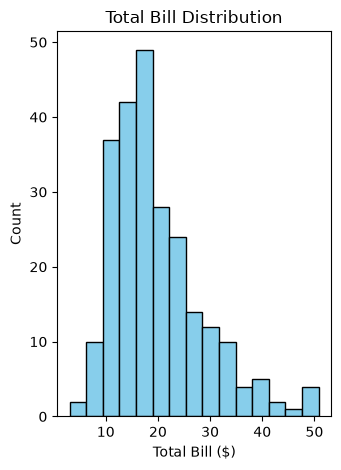

In [32]:
plt.subplot(1, 2, 1)
plt.hist(df['total_bill'], bins=15, color='skyblue', edgecolor='black')
plt.title('Total Bill Distribution')
plt.xlabel('Total Bill ($)')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

In [15]:
avg_tip = df["tip"].mean()
print(f"Average tip of this restaurant is: {round(avg_tip, 2)}$")

Average tip of this restaurant is: 3.0$


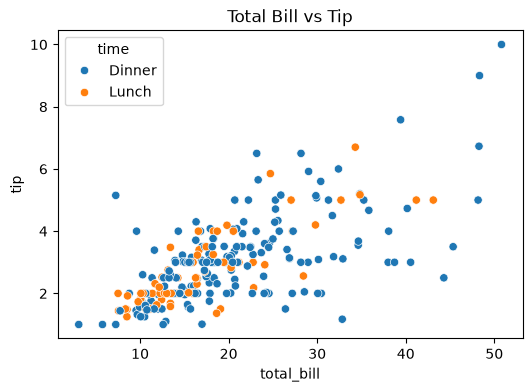

In [17]:
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x='total_bill', y='tip', hue='time')
plt.title('Total Bill vs Tip')
plt.show()

In [23]:
max_bill = df["total_bill"].max()
print(f"Max bill of this restaurant is: {max_bill}")

Max bill of this restaurant is: 50.81


In [28]:
avg_tip_by_day = df.groupby("day")["tip"].mean()
print("average tip by day is: ")
print(round(avg_tip_by_day, 2))

average tip by day is: 
day
Fri     2.73
Sat     2.99
Sun     3.26
Thur    2.77
Name: tip, dtype: float64


In [39]:
print("Top 5 highest tips")
print(df["tip"].sort_values(ascending= False).head(5))

Top 5 highest tips
170    10.00
212     9.00
23      7.58
59      6.73
141     6.70
Name: tip, dtype: float64


<Axes: xlabel='tip'>

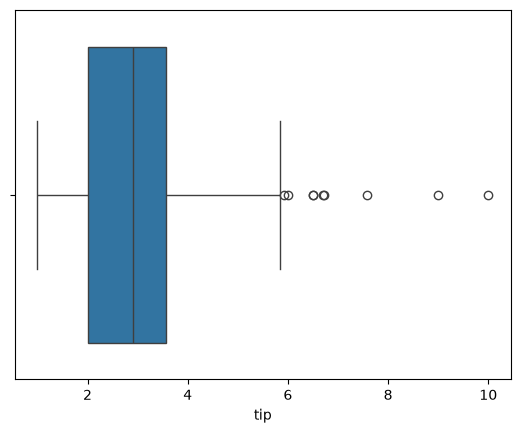

In [41]:
sns.boxplot(data = df, x = "tip")

In [35]:
q1 = df["tip"].quantile(0.25)
q3 = df["tip"].quantile(0.75)

iqr = q3 - q1

high = q3 + 1.5 * iqr

no_of_outliers = (df["tip"] > high).sum()

print(f"The upper range of tips is: {high} and the no. of outliers are: {no_of_outliers}")

The upper range of tips is: 5.90625 and the no. of outliers are: 9
